# Исследование надежности заемщиков


**Максим Лапин**

Заказчик исследования — кредитный отдел банка. Сравним долю записей с задолженностью по числу детей, семейному положению, месячному доходу и цели кредита. В данных debt = 1 означает, что у клиента была задолженность по возврату кредита.

Шаги 1 и 2 основаны на авторском решении из шаблона Практикума. Для запуска нужны Python 3, pandas, NumPy, SciPy и Matplotlib. Ноутбук использует data.csv рядом с собой, датасет на платформе или [официальную копию](https://code.s3.yandex.net/datasets/data.csv).

## Откройте таблицу и изучите общую информацию о данных

**Задание 1. Импортируйте библиотеку pandas. Считайте данные из csv-файла в датафрейм и сохраните в переменную `data`. Путь к файлу:**

`/datasets/data.csv`

In [1]:
from io import BytesIO
from pathlib import Path
from shutil import which
from subprocess import CalledProcessError, run

import pandas as pd

required_columns = {
    'children', 'days_employed', 'dob_years', 'education', 'education_id',
    'family_status', 'family_status_id', 'gender', 'income_type', 'debt',
    'total_income', 'purpose',
}
local_paths = [Path('data.csv'), Path('/datasets/data.csv')]
data_url = 'https://code.s3.yandex.net/datasets/data.csv'
source = next((path for path in local_paths if path.is_file()), data_url)

try:
    curl = which('curl')
    if source == data_url and curl:
        download = run([curl, '-fsSL', '--max-time', '45', data_url],
                       capture_output=True, check=True)
        source = BytesIO(download.stdout)
    data = pd.read_csv(source)
except (OSError, CalledProcessError, UnicodeError, pd.errors.ParserError, pd.errors.EmptyDataError) as error:
    raise RuntimeError('Не удалось прочитать датасет. Проверьте файл data.csv или доступ к источнику.') from error

missing_columns = required_columns.difference(data.columns)
if missing_columns:
    raise ValueError(f'В датасете нет столбцов: {", ".join(sorted(missing_columns))}')
if set(data['debt'].dropna().unique()) != {0, 1} or data['debt'].isna().any():
    raise ValueError('Столбец debt должен содержать две группы с метками 0 и 1.')

raw_data = data.copy()

**Задание 2. Выведите первые 20 строчек датафрейма `data` на экран.**

In [2]:
data.head(20)

,children,days_employed,dob_years,education,education_id,family_status,family_status_id,gender,income_type,debt,total_income,purpose
0,1,-8437.673028,42,высшее,0,женат / замужем,0,F,сотрудник,0,253875.639453,покупка жилья
1,1,-4024.803754,36,среднее,1,женат / замужем,0,F,сотрудник,0,112080.014102,приобретение автомобиля
2,0,-5623.422610,33,Среднее,1,женат / замужем,0,M,сотрудник,0,145885.952297,покупка жилья
3,3,-4124.747207,32,среднее,1,женат / замужем,0,M,сотрудник,0,267628.550329,дополнительное образование
4,0,340266.072047,53,среднее,1,гражданский брак,1,F,пенсионер,0,158616.077870,сыграть свадьбу
5,0,-926.185831,27,высшее,0,гражданский брак,1,M,компаньон,0,255763.565419,покупка жилья
6,0,-2879.202052,43,высшее,0,женат / замужем,0,F,компаньон,0,240525.971920,операции с жильем
7,0,-152.779569,50,СРЕДНЕЕ,1,женат / замужем,0,M,сотрудник,0,135823.934197,образование
8,2,-6929.865299,35,ВЫСШЕЕ,0,гражданский брак,1,F,сотрудник,0,95856.832424,на проведение свадьбы
9,0,-2188.756445,41,среднее,1,женат / замужем,0,M,сотрудник,0,144425.938277,покупка жилья для семьи


**Задание 3. Выведите основную информацию о датафрейме с помощью метода `info()`.**

In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 21525 entries, 0 to 21524
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   children          21525 non-null  int64  
 1   days_employed     19351 non-null  float64
 2   dob_years         21525 non-null  int64  
 3   education         21525 non-null  str    
 4   education_id      21525 non-null  int64  
 5   family_status     21525 non-null  str    
 6   family_status_id  21525 non-null  int64  
 7   gender            21525 non-null  str    
 8   income_type       21525 non-null  str    
 9   debt              21525 non-null  int64  
 10  total_income      19351 non-null  float64
 11  purpose           21525 non-null  str    
dtypes: float64(2), int64(5), str(5)
memory usage: 2.0 MB


## Предобработка данных

### Заполнение пропусков

**Задание 4. Выведите количество пропущенных значений для каждого столбца. Используйте комбинацию двух методов.**

In [4]:
data.isna().sum()

children               0
days_employed       2174
dob_years              0
education              0
education_id           0
family_status          0
family_status_id       0
gender                 0
income_type            0
debt                   0
total_income        2174
purpose                0
dtype: int64

**Задание 5. В двух столбцах есть пропущенные значения. Один из них — `days_employed`. Пропуски в этом столбце вы обработаете на следующем этапе. Другой столбец с пропущенными значениями — `total_income` — хранит данные о доходах. На сумму дохода сильнее всего влияет тип занятости, поэтому заполнить пропуски в этом столбце нужно медианным значением по каждому типу из столбца `income_type`. Например, у человека с типом занятости `сотрудник` пропуск в столбце `total_income` должен быть заполнен медианным доходом среди всех записей с тем же типом.**

In [5]:
for t in data['income_type'].unique():
    data.loc[(data['income_type'] == t) & (data['total_income'].isna()), 'total_income'] = \
    data.loc[(data['income_type'] == t), 'total_income'].median()

### Обработка аномальных значений

**Задание 6. В данных могут встречаться артефакты (аномалии) — значения, которые не отражают действительность и появились по какой-то ошибке. таким артефактом будет отрицательное количество дней трудового стажа в столбце `days_employed`. Для реальных данных это нормально. Обработайте значения в этом столбце: замените все отрицательные значения положительными с помощью метода `abs()`.**

In [6]:
data['days_employed'] = data['days_employed'].abs()

**Задание 7. Для каждого типа занятости выведите медианное значение трудового стажа `days_employed` в днях.**

In [7]:
data.groupby('income_type')['days_employed'].agg('median')

income_type
безработный        366413.652744
в декрете            3296.759962
госслужащий          2689.368353
компаньон            1547.382223
пенсионер          365213.306266
предприниматель       520.848083
сотрудник            1574.202821
студент               578.751554
Name: days_employed, dtype: float64

У двух типов (безработные и пенсионеры) получатся аномально большие значения. Исправить такие значения сложно, поэтому оставьте их как есть.

**Задание 8. Выведите перечень уникальных значений столбца `children`.**

In [8]:
data['children'].unique()

array([ 1,  0,  3,  2, -1,  4, 20,  5])

**Задание 9. В столбце `children` есть два аномальных значения. Удалите строки, в которых встречаются такие аномальные значения из датафрейма `data`.**

In [9]:
data = data[(data['children'] != -1) & (data['children'] != 20)]

**Задание 10. Ещё раз выведите перечень уникальных значений столбца `children`, чтобы убедиться, что артефакты удалены.**

In [10]:
data['children'].unique()

array([1, 0, 3, 2, 4, 5])

### Заполнение пропусков в стаже

**Задание 11. Заполните пропуски в столбце `days_employed` медианными значениями по каждого типа занятости `income_type`.**

In [11]:
for t in data['income_type'].unique():
    data.loc[(data['income_type'] == t) & (data['days_employed'].isna()), 'days_employed'] = \
    data.loc[(data['income_type'] == t), 'days_employed'].median()

**Задание 12. Убедитесь, что все пропуски заполнены. Проверьте себя и ещё раз выведите количество пропущенных значений для каждого столбца с помощью двух методов.**

In [12]:
data.isna().sum()

children            0
days_employed       0
dob_years           0
education           0
education_id        0
family_status       0
family_status_id    0
gender              0
income_type         0
debt                0
total_income        0
purpose             0
dtype: int64

### Изменение типов данных

**Задание 13. Замените вещественный тип данных в столбце `total_income` на целочисленный с помощью метода `astype()`.**

In [13]:
data['total_income'] = data['total_income'].astype(int)

### Обработка дубликатов

**Задание 14. Обработайте неявные дубликаты в столбце `education`. В этом столбце есть одни и те же значения, но записанные по-разному: с использованием заглавных и строчных букв. Приведите их к нижнему регистру.**

In [14]:
data['education'] = data['education'].str.lower()

**Задание 15. Выведите на экран количество строк-дубликатов в данных. Если такие строки присутствуют, удалите их.**

In [15]:
duplicate_count = data.duplicated().sum()
print(f'Полных дубликатов после предобработки: {duplicate_count}')

Полных дубликатов после предобработки: 71


In [16]:
data = data.drop_duplicates()

### Категоризация данных

**Задание 16. На основании диапазонов, указанных ниже, создайте в датафрейме `data` столбец `total_income_category` с категориями:**

- 0–30000 — `'E'`;
- 30001–50000 — `'D'`;
- 50001–200000 — `'C'`;
- 200001–1000000 — `'B'`;
- 1000001 и выше — `'A'`.


**Например, кредитополучателю с доходом 25000 нужно назначить категорию `'E'`, а клиенту, получающему 235000, — `'B'`. Используйте собственную функцию с именем `categorize_income()` и метод `apply()`.**

In [17]:
def categorize_income(income):
    if 0 <= income <= 30_000:
        return 'E'
    if 30_001 <= income <= 50_000:
        return 'D'
    if 50_001 <= income <= 200_000:
        return 'C'
    if 200_001 <= income <= 1_000_000:
        return 'B'
    if income >= 1_000_001:
        return 'A'
    raise ValueError(f'Доход вне заданных диапазонов: {income}')

In [18]:
data['total_income_category'] = data['total_income'].apply(categorize_income)

**Задание 17. Выведите на экран перечень уникальных целей взятия кредита из столбца `purpose`.**

In [19]:
data['purpose'].unique()

<StringArray>
[                         'покупка жилья',
                'приобретение автомобиля',
             'дополнительное образование',
                        'сыграть свадьбу',
                      'операции с жильем',
                            'образование',
                  'на проведение свадьбы',
                'покупка жилья для семьи',
                   'покупка недвижимости',
      'покупка коммерческой недвижимости',
             'покупка жилой недвижимости',
 'строительство собственной недвижимости',
                           'недвижимость',
             'строительство недвижимости',
     'на покупку подержанного автомобиля',
           'на покупку своего автомобиля',
  'операции с коммерческой недвижимостью',
       'строительство жилой недвижимости',
                                  'жилье',
        'операции со своей недвижимостью',
                             'автомобили',
                  'заняться образованием',
       'сделка с подержанным автомобилем

**Задание 18. Создайте функцию, которая на основании данных из столбца `purpose` сформирует новый столбец `purpose_category`, в который войдут следующие категории:**

- `'операции с автомобилем'`,
- `'операции с недвижимостью'`,
- `'проведение свадьбы'`,
- `'получение образования'`.

**Например, если в столбце `purpose` находится подстрока `'на покупку автомобиля'`, то в столбце `purpose_category` должна появиться строка `'операции с автомобилем'`.**

**Используйте собственную функцию с именем `categorize_purpose()` и метод `apply()`. Изучите данные в столбце `purpose` и определите, какие подстроки помогут вам правильно определить категорию.**

In [20]:
def categorize_purpose(purpose):
    if 'автом' in purpose:
        return 'операции с автомобилем'
    if 'жил' in purpose or 'недвиж' in purpose:
        return 'операции с недвижимостью'
    if 'свад' in purpose:
        return 'проведение свадьбы'
    if 'образов' in purpose:
        return 'получение образования'
    raise ValueError(f'Не удалось определить категорию цели: {purpose}')

In [21]:
data['purpose_category'] = data['purpose'].apply(categorize_purpose)

Сохранили границы дохода из задания, чтобы сравнивать фиксированные диапазоны месячного дохода. Для целей использовали общие основы слов: «автом» для автомобиля, «жил» и «недвиж» для жилья и недвижимости, «свад» для свадьбы, «образов» для образования. Такой словарь объединяет разные формулировки одной цели. Ниже проверим, что каждая исходная формулировка попала в одну из четырёх групп.

Из 21 525 строк исключили 123 с аномальным числом детей (−1 или 20) и 71 полный дубликат после заполнения пропусков и нормализации регистра образования. В анализе осталась 21 331 запись. Аномально большой стаж у пенсионеров и безработных оставили по условию. Стаж в сравнениях задолженности далее не используется.

In [22]:
if data.isna().any().any() or data.duplicated().any():
    raise ValueError('После предобработки остались пропуски или полные дубликаты.')

display(pd.Series({
    'Строк до очистки': len(raw_data),
    'Исключено по числу детей': raw_data['children'].isin([-1, 20]).sum(),
    'Исключено полных дубликатов': duplicate_count,
    'Строк после очистки': len(data),
    'Уникальных формулировок цели': data['purpose'].nunique(),
    'Категорий цели': data['purpose_category'].nunique(),
}, name='Количество').to_frame())

display(data.groupby('purpose_category')['purpose'].nunique()
        .rename('Уникальных исходных формулировок').to_frame())

,Количество
Строк до очистки,21525
Исключено по числу детей,123
Исключено полных дубликатов,71
Строк после очистки,21331
Уникальных формулировок цели,38
Категорий цели,4


,Уникальных исходных формулировок
purpose_category,
операции с автомобилем,9
операции с недвижимостью,17
получение образования,9
проведение свадьбы,3


### Шаг 3. Исследуйте данные и ответьте на вопросы

Для каждой группы считаем число записей, число записей с задолженностью и долю задолженности. На графиках показываем 95%-ные интервалы Уилсона для долей. Пунктир обозначает долю задолженности по всему очищенному набору. Ширина интервалов помогает оценить точность доли в группах разного размера.

Для четырёх основных сравнений используем критерий χ² Пирсона. Нулевая гипотеза в каждом сравнении состоит в том, что доля задолженности одинакова во всех сравниваемых группах. Для редких соседних категорий применяем объединение, описанное в соответствующих разделах. Порог для четырёх проверок с поправкой Бонферрони составляет 0,05 / 4 = 0,0125. Величину связи показываем коэффициентом V Крамера, а наблюдаемые различия между группами — в процентных пунктах. Дополнительная проверка непрерывного дохода носит исследовательский характер.

In [23]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

def debt_summary(group):
    table = pd.pivot_table(
        data, index=group, values='debt',
        aggfunc=['count', 'sum', 'mean'], observed=True,
    )
    table.columns = ['Записей', 'С задолженностью', 'Доля, %']
    table['Доля, %'] *= 100

    limits = [
        stats.binomtest(int(debts), int(total)).proportion_ci(method='wilson')
        for total, debts in zip(table['Записей'], table['С задолженностью'])
    ]
    table['Нижняя граница, %'] = [100 * limit.low for limit in limits]
    table['Верхняя граница, %'] = [100 * limit.high for limit in limits]
    return table


def show_debt_summary(table, title):
    display(table.round(2))
    rate = table['Доля, %']
    lower_error = (rate - table['Нижняя граница, %']).clip(lower=0)
    upper_error = (table['Верхняя граница, %'] - rate).clip(lower=0)
    labels = [f'{name} (n={n:,})'.replace(',', ' ') for name, n in table['Записей'].items()]

    fig, ax = plt.subplots(figsize=(8.2, max(3.2, len(table) * 0.52 + 1.6)),
                          constrained_layout=True)
    ax.barh(labels, rate, color='#28746e', xerr=[lower_error, upper_error],
            error_kw={'ecolor': '#253745', 'capsize': 3})
    ax.axvline(100 * data['debt'].mean(), color='#565d66', linestyle='--',
               linewidth=1.2)
    ax.set_xlim(left=0)
    ax.invert_yaxis()
    ax.set(title=title, xlabel='Доля записей с задолженностью, %\nПунктир — доля по всему набору')
    plt.show()


def test_independence(group, debt):
    counts = pd.crosstab(group, debt)
    result = stats.chi2_contingency(counts, correction=False)
    min_expected = result.expected_freq.min()
    if min_expected < 5:
        raise ValueError(f'Для критерия χ² слишком мала ожидаемая частота: {min_expected:.2f}')
    n = counts.to_numpy().sum()
    k = min(counts.shape) - 1
    effect = np.sqrt(result.statistic / (n * k))
    return pd.Series({
        'χ²': result.statistic,
        'Степени свободы': int(result.dof),
        'p-значение': result.pvalue,
        'V Крамера': effect,
        'Мин. ожидаемая частота': min_expected,
    })

#### 3.1 Есть ли зависимость между количеством детей и возвратом кредита в срок?

,Записей,С задолженностью,"Доля, %","Нижняя граница, %","Верхняя граница, %"
children,,,,,
0,14091,1063,7.54,7.12,7.99
1,4808,444,9.23,8.45,10.09
2,2052,194,9.45,8.26,10.80
3,330,27,8.18,5.68,11.64
4,41,4,9.76,3.86,22.55
5,9,0,0.00,0.00,29.91


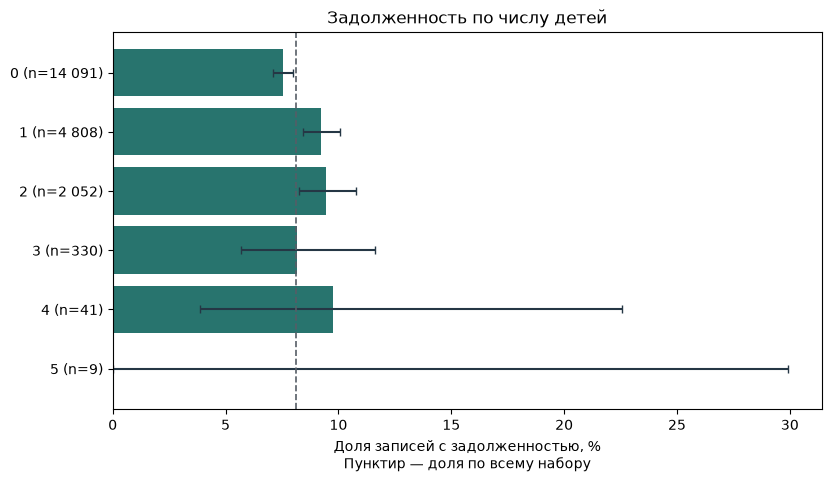

,Число детей
χ²,19.173909
Степени свободы,3.000000
p-значение,0.000252
V Крамера,0.029981
Мин. ожидаемая частота,30.854625


In [24]:
children_summary = debt_summary('children').sort_index()
show_debt_summary(children_summary, 'Задолженность по числу детей')

children_group = data['children'].clip(upper=3).map(
    {0: '0', 1: '1', 2: '2', 3: '3 и более'}
)
children_test = test_independence(children_group, data['debt'])
display(children_test.to_frame('Число детей'))

**Вывод.** Среди записей без детей задолженность наблюдалась в 7,54% случаев, с одним ребёнком — в 9,23%, с двумя — в 9,45%. Разница с группой без детей составляет 1,69 и 1,91 процентного пункта соответственно. Среди записей с пятью детьми задолженностей не было, но в этой группе всего 9 наблюдений. Верхняя граница 95%-ного интервала составляет около 30%.

Для общей проверки объединили группы с тремя и более детьми: без объединения ожидаемое число записей с задолженностью в группах с 4 и 5 детьми меньше пяти. Критерий показывает связь в этих четырёх группах (p = 0,000252, V = 0,030). По отдельным группам с четырьмя и пятью детьми оценки слишком неточны для выводов о порядке рисков.

#### 3.2 Есть ли зависимость между семейным положением и возвратом кредита в срок?

,Записей,С задолженностью,"Доля, %","Нижняя граница, %","Верхняя граница, %"
family_status,,,,,
Не женат / не замужем,2796,273,9.76,8.72,10.92
гражданский брак,4134,385,9.31,8.46,10.24
женат / замужем,12261,927,7.56,7.11,8.04
в разводе,1189,84,7.06,5.74,8.66
вдовец / вдова,951,63,6.62,5.21,8.39


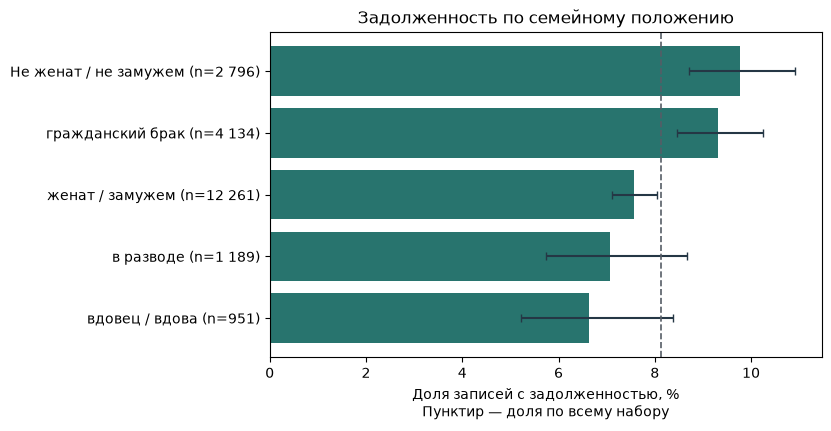

,Семейное положение
χ²,27.784523
Степени свободы,4.000000
p-значение,0.000014
V Крамера,0.036091
Мин. ожидаемая частота,77.217758


In [25]:
family_summary = debt_summary('family_status').sort_values('Доля, %', ascending=False)
show_debt_summary(family_summary, 'Задолженность по семейному положению')

family_test = test_independence(data['family_status'], data['debt'])
display(family_test.to_frame('Семейное положение'))

**Вывод.** Доля задолженности выше у не состоящих в браке (9,76%) и у указавших гражданский брак (9,31%). В группе «женат / замужем» — 7,56%, в разводе — 7,06%, у вдов и вдовцов — 6,62%. Между крайними долями разница 3,14 процентного пункта. Общая связь обнаруживается (p = 0,0000138, V = 0,036). Возраст, занятость и другие различия между группами могут объяснять часть разницы.

#### 3.3 Есть ли зависимость между уровнем дохода и возвратом кредита в срок?

,Записей,С задолженностью,"Доля, %","Нижняя граница, %","Верхняя граница, %"
total_income_category,,,,,
E,22,2,9.09,2.53,27.81
D,349,21,6.02,3.97,9.02
C,15921,1353,8.50,8.08,8.94
B,5014,354,7.06,6.38,7.80
A,25,2,8.00,2.22,24.97


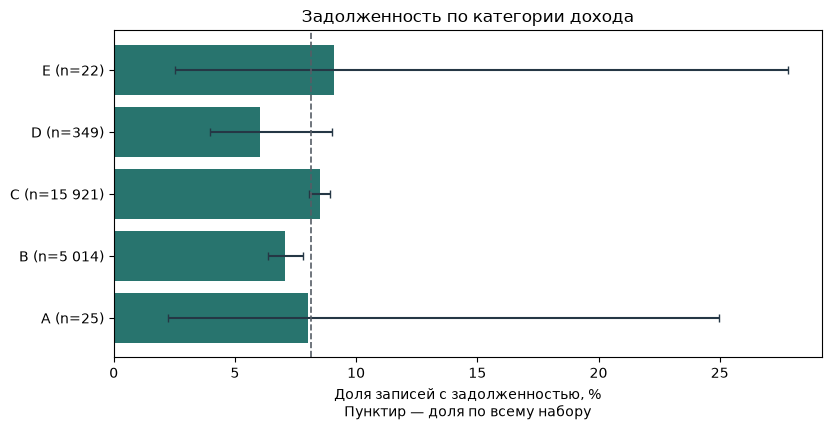

,Категория дохода
χ²,12.406203
Степени свободы,2.000000
p-значение,0.002023
V Крамера,0.024116
Мин. ожидаемая частота,30.123857


In [26]:
income_summary = debt_summary('total_income_category').reindex(list('EDCBA'))
show_debt_summary(income_summary, 'Задолженность по категории дохода')

# Для общего теста объединяем редкие крайние категории с соседними.
income_group = data['total_income_category'].map(
    {'E': 'E и D', 'D': 'E и D', 'C': 'C', 'B': 'B и A', 'A': 'B и A'}
)
income_test = test_independence(income_group, data['debt'])
display(income_test.to_frame('Категория дохода'))

Медианная подстановка образует повторяющиеся значения. Проверим, насколько она влияет на сравнение доходов. Для этого оставим очищенные записи, у которых доход был указан в исходном файле, и отдельно сравним распределения дохода по признаку задолженности. На диаграмме размаха используем логарифмическую шкалу из-за длинного правого хвоста.

,Записей с известным доходом,"Доля задолженности, %"
total_income_category,,
E,22,9.09
D,349,6.02
C,13831,8.55
B,5013,7.06
A,25,8.00


,Записей,Медиана,Среднее
debt,,,
Без задолженности,17678,145166.0,167832.07
С задолженностью,1562,143037.5,163104.81


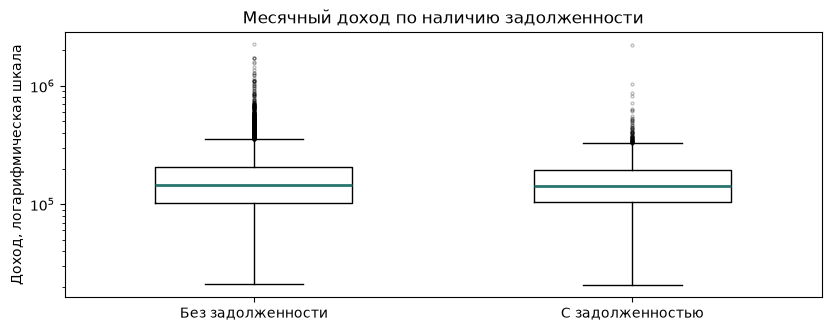

,Доход без подстановок
U Манна — Уитни,1.353785e+07
p-значение,2.016587e-01
Ранговая бисериальная корреляция,-1.945958e-02
p-значение χ² по категориям,1.650292e-03


In [27]:
observed_income = data.loc[raw_data.loc[data.index, 'total_income'].notna()]
income_comparison = observed_income.groupby('total_income_category')['debt'].agg(
    ['size', 'mean']
).reindex(list('EDCBA'))
income_comparison['mean'] *= 100
income_comparison.columns = ['Записей с известным доходом', 'Доля задолженности, %']
display(income_comparison.round(2))

loans_without_debt = observed_income.loc[observed_income['debt'].eq(0), 'total_income']
loans_with_debt = observed_income.loc[observed_income['debt'].eq(1), 'total_income']
display(observed_income.groupby('debt')['total_income'].agg(['size', 'median', 'mean'])
        .rename(index={0: 'Без задолженности', 1: 'С задолженностью'},
                columns={'size': 'Записей', 'median': 'Медиана', 'mean': 'Среднее'}).round(2))

fig, ax = plt.subplots(figsize=(8.2, 3.2), constrained_layout=True)
ax.boxplot([loans_without_debt, loans_with_debt], widths=0.52,
           medianprops={'color': '#28746e', 'linewidth': 2},
           flierprops={'markersize': 2, 'alpha': 0.25})
ax.set_xticks([1, 2], ['Без задолженности', 'С задолженностью'])
ax.set_yscale('log')
ax.set(title='Месячный доход по наличию задолженности',
       ylabel='Доход, логарифмическая шкала')
plt.show()

income_u = stats.mannwhitneyu(loans_with_debt, loans_without_debt, alternative='two-sided')
rank_effect = 2 * income_u.statistic / (len(loans_with_debt) * len(loans_without_debt)) - 1
observed_income_test = test_independence(
    income_group.loc[observed_income.index], observed_income['debt']
)
display(pd.Series({
    'U Манна — Уитни': income_u.statistic,
    'p-значение': income_u.pvalue,
    'Ранговая бисериальная корреляция': rank_effect,
    'p-значение χ² по категориям': observed_income_test['p-значение'],
}, name='Доход без подстановок').to_frame())

**Вывод.** В двух крупнейших группах задолженность встречалась в 8,50% записей категории C (50 001–200 000) и 7,06% категории B (200 001–1 000 000). Разница — 1,44 процентного пункта. Без записей с заполненным доходом получили 8,55% и 7,06%, то есть направление и масштаб разницы сохранились.

В крайних категориях E и A только 22 и 25 наблюдений. Для общего теста присоединили их к соседним группам D и B соответственно. В таком сравнении доли различаются (p = 0,00202, V = 0,024). Критерий Манна — Уитни для известных значений дохода не выявил статистически значимого рангового сдвига при пороге 0,05 (p = 0,202, ранговый эффект −0,019). Категориальное сравнение и ранговый тест отвечают на разные вопросы. По этим данным нельзя считать, что с каждым ростом дохода вероятность задолженности снижается.

#### 3.4 Как разные цели кредита влияют на его возврат в срок?

,Записей,С задолженностью,"Доля, %","Нижняя граница, %","Верхняя граница, %"
purpose_category,,,,,
операции с автомобилем,4279,400,9.35,8.51,10.26
получение образования,3988,369,9.25,8.39,10.19
проведение свадьбы,2313,183,7.91,6.88,9.08
операции с недвижимостью,10751,780,7.26,6.78,7.76


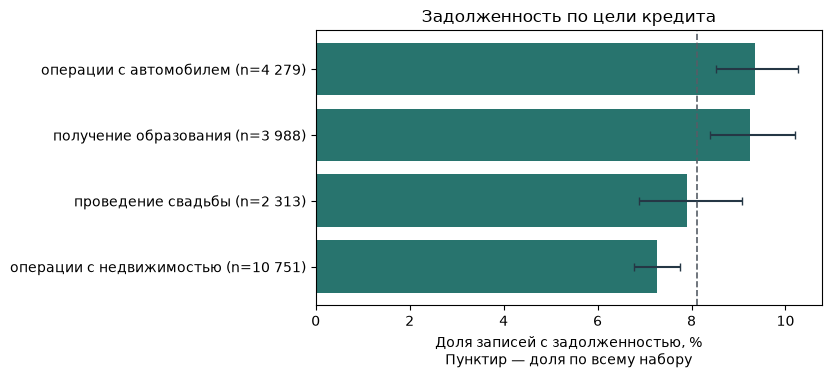

,Цель кредита
χ²,26.421596
Степени свободы,3.000000
p-значение,0.000008
V Крамера,0.035194
Мин. ожидаемая частота,187.807229


In [28]:
purpose_summary = debt_summary('purpose_category').sort_values('Доля, %', ascending=False)
show_debt_summary(purpose_summary, 'Задолженность по цели кредита')

purpose_test = test_independence(data['purpose_category'], data['debt'])
display(purpose_test.to_frame('Цель кредита'))

**Вывод.** Наибольшие доли задолженности наблюдались у кредитов на автомобиль (9,35%) и образование (9,25%). У кредитов на свадьбу — 7,91%, на недвижимость — 7,26%. Между автомобилем и недвижимостью разница 2,09 процентного пункта. Общая связь статистически заметна (p = 0,00000778, V = 0,035). Разницу могут частично объяснять условия продуктов: срок, сумма, обеспечение или правила одобрения. Для сравнения этих объяснений соответствующие данные нужны отдельно.

#### 3.5 Приведите возможные причины появления пропусков в исходных данных.

In [29]:
missing = raw_data[['total_income', 'days_employed']].isna()
display(pd.crosstab(missing['days_employed'], missing['total_income'],
                    rownames=['Стаж пропущен'], colnames=['Доход пропущен']))
missing_by_job = (raw_data.assign(income_missing=missing['total_income'])
                  .groupby('income_type')['income_missing'].agg(['size', 'sum', 'mean']))
missing_by_job['mean'] *= 100
display(missing_by_job.rename(columns={'size': 'Записей', 'sum': 'С пропуском',
                                      'mean': 'Доля пропусков, %'}).round(2))

Доход пропущен,False,True
Стаж пропущен,,
False,19351,0
True,0,2174


,Записей,С пропуском,"Доля пропусков, %"
income_type,,,
безработный,2,0,0.00
в декрете,1,0,0.00
госслужащий,1459,147,10.08
компаньон,5085,508,9.99
пенсионер,3856,413,10.71
предприниматель,2,1,50.00
сотрудник,11119,1105,9.94
студент,1,0,0.00


**Ответ.** В 2 174 строках из 21 525 (10,10%) одновременно отсутствуют доход и стаж. Строк с пропуском только одного из этих полей нет. Это наблюдение согласуется с тем, что оба поля могут приходить из одного источника или заполняться вместе. Возможные причины — клиент не представил сведения о занятости, поля были необязательными в части заявок либо блок потерялся при выгрузке или объединении источников. Подтвердить причину можно по правилам анкеты, журналу загрузки и разрезам по времени и каналу оформления. Одинаковый набор пропусков в двух столбцах сам по себе не устанавливает их причину.

#### 3.6 Объясните, почему заполнить пропуски медианным значением — лучшее решение для количественных переменных.

**Ответ.** Для этих данных медиана подходит как простая оценка типичного значения. В исходном столбце доходов медиана около 145 тыс., среднее около 167 тыс., а максимум превышает 2,26 млн. Крупные значения сильнее сдвигают среднее. Медиана зависит от положения наблюдений в упорядоченном ряду и лучше сохраняет типичный уровень при таком правом хвосте. Заполнение по типу занятости учитывает, что типичные доходы групп различаются, например около 119 тыс. у пенсионеров и 172 тыс. у компаньонов.

У этого способа есть ограничения. Подставленные значения уменьшают разброс, могут массово переместить записи в одну категорию и давать смещение, если вероятность пропуска связана с самим доходом. В очищенных данных в категорию C попали 2 090 из 2 091 записей с подставленным доходом. Поэтому сравнение проверено и на записях с исходным доходом. Для построения модели стоило бы отдельно проверить индикатор пропуска и считать медианы только на обучающей выборке.

### Шаг 4: общий вывод.

После предобработки в анализ вошла 21 331 запись, из них 1 732 с задолженностью (8,12%). По четырём основным сравнениям p-значения ниже порога 0,0125. Коэффициент V Крамера составляет от 0,024 до 0,036. Связи небольшие, хотя некоторые различия достигают примерно двух-трёх случаев задолженности на каждые 100 записей.

- Задолженность чаще встречалась в группах с одним и двумя детьми, чем в группе без детей. Данные по четырём и пяти детям слишком редки для устойчивых оценок.
- По семейному положению доли различались на 3,14 процентного пункта между крайними группами.
- Категория B показала меньшую долю задолженности, чем категория C. Разница сохранилась после исключения записей с подставленным доходом.
- Среди целей кредита наибольшие доли наблюдались для автомобиля и образования, для недвижимости доля была самой низкой.

Полученные связи описывают выданный набор. Без данных об отклонённых заявках и периоде наблюдения неизвестно, перенесутся ли оценки на новых заявителей. Расчёты предполагают независимость записей. Идентификаторов клиентов нет, поэтому нельзя проверить повторные обращения одного человека и установить причину полного совпадения отдельных записей. Доход, возраст, занятость, условия кредита и семейное положение могут быть связаны между собой, поэтому из этих сравнений нельзя сделать причинный вывод.

Для скоринга стоит сравнить на более поздней выборке базовую модель и модель с доходом, индикатором пропуска дохода и категорией цели кредита. Проверить, улучшились ли калибровка вероятностей и качество ранжирования. Запросить сумму, срок, платежи, долговую нагрузку, дату выдачи и идентификатор клиента, чтобы исключить пересечение клиентов между выборками. Связи с семейным положением и числом детей стоит проверять с учётом возраста и условий кредита, а доступность таких признаков для скоринга — согласовать с подразделениями риска и комплаенса.